In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xpsi

/=============================================\
| X-PSI: X-ray Pulse Simulation and Inference |
|---------------------------------------------|
|               Version: 3.5.0b1              |
|---------------------------------------------|
|      https://xpsi-group.github.io/xpsi      |
\=============================================/

Imported GetDist version: 1.7.7
Imported nestcheck version: 0.2.1


/home/yves/envs/xpsi_hack/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import main as model

Setting channels for event data...
Channels set.
Setting channels for loaded instrument response (sub)matrix...
Channels set.
An empty subspace was created. This is normal behavior - no parameters were supplied.
Creating parameter:
    > Named "phase_shift" with fixed value 0.000e+00.
    > The phase shift for the signal, a periodic parameter [cycles].
Creating parameter:
    > Named "frequency" with fixed value 3.140e+02.
    > Spin frequency [Hz].
Creating parameter:
    > Named "mass" with bounds [1.000e+00, 1.600e+00].
    > Gravitational mass [solar masses].
Creating parameter:
    > Named "radius" with bounds [1.000e+01, 1.300e+01].
    > Coordinate equatorial radius [km].
Creating parameter:
    > Named "distance" with bounds [5.000e-01, 2.000e+00].
    > Earth distance [kpc].
Creating parameter:
    > Named "cos_inclination" with bounds [0.000e+00, 1.000e+00].
    > Cosine of Earth inclination to rotation axis.
Creating parameter:
    > Named "super_colatitude" with bounds [1.0

In [5]:
samples = model.prior.draw(1000)[0]

Drawing samples from the joint prior...
Samples drawn.


In [6]:
samples

array([[ 1.57579963, 12.53007642,  1.21645445, ...,  0.71359945,
         1.01269699,  6.4886833 ],
       [ 1.3196251 , 10.98437571,  1.12367759, ...,  1.11781798,
         0.43050883,  6.82592555],
       [ 1.54361186, 11.05769927,  1.09222642, ...,  0.96910717,
         0.84864176,  6.23012487],
       ...,
       [ 1.31199622, 11.54248434,  0.8476009 , ...,  1.41578948,
         0.63653273,  6.96658022],
       [ 1.43513901, 12.18624311,  1.05113461, ...,  1.06505727,
         0.02820312,  6.97561173],
       [ 1.10005664, 11.21321535,  1.05303622, ...,  1.54644879,
         0.64452957,  6.39171568]], shape=(1000, 8))

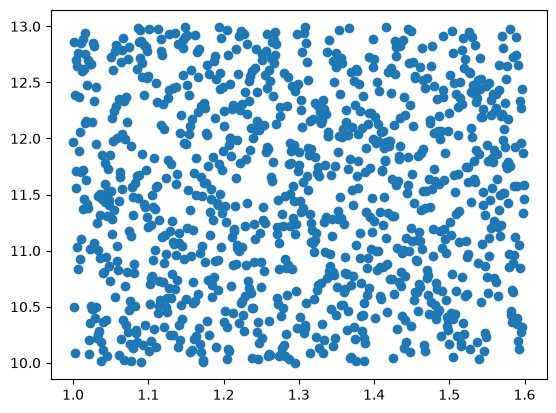

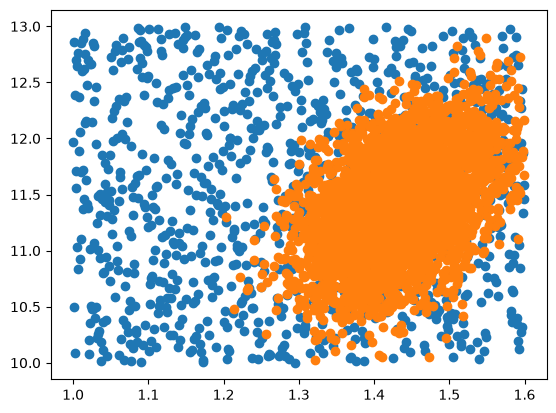

In [43]:
init_samples = np.loadtxt("../Outputs/ST_ptemcee_initial_walkers.txt")
temp, walker, params = init_samples[:, 0], init_samples[:, 1], init_samples[:, 2:]

#params[:, 2]               # mass, all walkers at all temperatures
#params= params[temp == 1]          # cold-chain walkers only
plt.scatter(samples[:,0], samples[:,1])
plt.scatter(params[:, 0], params[:, 1])

In [44]:
M_out = np.loadtxt('../Outputs/ST_live_1000_eff_0.3_seed0.txt')

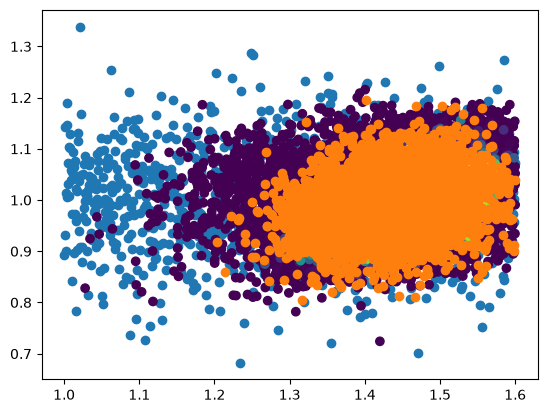

In [46]:
plt.scatter(samples[:,0], samples[:,2])

plt.scatter(M_out[:,2], M_out[:,4], c=M_out[:,0])
plt.scatter(params[:, 0], params[:, 2])
#plt.scatter(params[:, 0], params[:, 1])